# Assignment 1 - Multilayer Perceptron from Scratch

This notebook develops the first assignment in the Deep Learning (DEEP01). Here, we will derive and develop a complete multilayer perceptron from zero. The first step is to import the dataset requested in the assignment.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Generate a reproducible two-class dataset.
X, y = make_moons(
    n_samples=420,
    noise=0.17,
    random_state=11
)

# Preserve the class balance in the train/test split.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=11
)


## Input Standardization

Firstly, we standardize each input using $$X_{std} = \frac{X-\mu}{s} \qquad \mu,s \in \mathbb{R^{1\times2}}$$ where $\mu$ and $s$ are the column-wise mean and standard deviation of X_train. We apply the same parameters to X_test, as they are, and to the grid points used in the figures.

In [3]:
# Standardize using training statistics only
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

X_train = (X_train - X_mean) / X_std
X_test = (X_test - X_mean) / X_std

# Convert labels into column vectors
Y_train = y_train.reshape(-1, 1).astype(np.float64)
Y_test = y_test.reshape(-1, 1).astype(np.float64)

# Ensure float64 computations
X_train = X_train.astype(np.float64)
X_test = X_test.astype(np.float64)

print("Training input:", X_train.shape)
print("Training labels:", Y_train.shape)
print("Test input:", X_test.shape)
print("Test labels:", Y_test.shape)

Training input: (315, 2)
Training labels: (315, 1)
Test input: (105, 2)
Test labels: (105, 1)


## Notation and Matrix Dimensions

We use the notation:

$$
d\theta := \frac{\partial J}{\partial \theta}
$$

where $\theta$ represents a trainable parameter or an intermediate variable.


## Activity 1 - Deriving the Forward Pass


### First Layer - Linear Transformation

The first layer performs a linear transformation of the input features:

$$
\mathbf{Z}_1 = \mathbf{XW}_1 + \mathbf{1b}_1
$$

The matrix multiplication has dimensions:

$$
(m \times 2)(2 \times 4) + (m \times 1)(1 \times 4)
= m \times 4
$$

Therefore, $\mathbf{Z}_1 \in \mathbb{R}^{m \times 4}$.

This means that each of the four hidden neurons computes a weighted sum of the two input features and adds its corresponding bias. Each row of $\mathbf{Z}_1$ contains the linear transformation results for one sample.

### Second Layer - ReLU Activation

Next, we apply the ReLU activation function, which was discussed in the initial lectures:

$$
ReLU(z) = \max(0,z)
$$

Equivalently, it can be expressed as:

$$
ReLU(z) =
\begin{cases}
z & z > 0 \\
0 & z \leq 0
\end{cases}
$$

Applying this activation function to the output of the first linear transformation gives:

$$
\mathbf{A}_1 = ReLU(\mathbf{Z}_1)
$$

This operation is performed elementwise, meaning that the activation function is independently applied to every element of $\mathbf{Z}_1$. Consequently, the dimensions remain unchanged:

$$
\mathbf{A}_1 \in \mathbb{R}^{m \times 4}
$$

The ReLU activation introduces nonlinearity into the network, allowing it to learn more complex decision boundaries than a purely linear model.

### Third Layer - Output Linear Transformation

The activations from the hidden layer are passed through a second linear transformation:

$$
\mathbf{Z}_2 = \mathbf{A}_1\mathbf{W}_2 + \mathbf{1b}_2
$$

Considering the dimensions:

$$
(m \times 4)(4 \times 1) + (m \times 1)(1 \times 1)
= m \times 1
$$

Therefore, $\mathbf{Z}_2 \in \mathbb{R}^{m \times 1}$.

Each sample now has one output value, representing the network's prediction before applying the final activation function. These values are also known as logits.

### Fourth Layer - Sigmoid Activation

Since this is a binary classification problem, we use the sigmoid activation function to convert the output logits into probabilities:

$$
\sigma(z) = \frac{1}{1+e^{-z}}
$$

Applying it elementwise gives:

$$
\hat{\mathbf{Y}} = \sigma(\mathbf{Z}_2)
$$

The resulting matrix has dimensions:

$$
\hat{\mathbf{Y}} \in \mathbb{R}^{m \times 1}
$$

Each element of $\hat{\mathbf{Y}}$ represents the predicted probability that the corresponding sample belongs to class 1. A prediction can be converted into a binary class using a threshold of 0.5:

$$
\hat{y}_i =
\begin{cases}
1 & \hat{y}_i \geq 0.5 \\
0 & \hat{y}_i < 0.5
\end{cases}
$$



## BCE + L2 Loss Derivation

### Binary Cross-Entropy Loss

To evaluate the predictions, we use the Binary Cross-Entropy (BCE) loss. For a single sample, the loss is defined as:

$$
\ell_i =
-\left[
y_i\log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
$$

This function compares the predicted probability with the actual label. When the actual label is 1, the loss penalizes low predicted probabilities. Conversely, when the actual label is 0, it penalizes high predicted probabilities.

For a batch of $m$ samples, the mean BCE loss is:

$$
J_{BCE} =
-\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i\log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
$$

Since the network uses a sigmoid output, the loss can also be expressed directly in terms of the logits $z_i$, where $z_i$ is the $i$-th element of $\mathbf{Z}_2$.

Using the sigmoid definition:

$$
\log(\sigma(z_i)) =
-\log(1+e^{-z_i})
$$

and

$$
\log(1-\sigma(z_i)) =
-z_i-\log(1+e^{-z_i})
$$

Substituting these expressions into the BCE equation gives:

$$
\ell_i =
(1-y_i)z_i + \log(1+e^{-z_i})
$$

An equivalent numerically stable expression is:

$$
\ell_i =
\max(z_i,0)
-y_i z_i
+\log(1+e^{-|z_i|})
$$

Therefore, the mean BCE can be calculated as:

$$
J_{BCE} =
\frac{1}{m}
\sum_{i=1}^{m}
\left[
\max(z_i,0)
-y_i z_i
+\log(1+e^{-|z_i|})
\right]
$$

This formulation avoids directly evaluating logarithms of probabilities that may be numerically equal to zero or one. It is particularly useful when implementing the loss function.

To verify the equivalence, consider the two possible signs of $z_i$.

**Case 1: $z_i \geq 0$.**

In this case, $\max(z_i,0)=z_i$ and $|z_i|=z_i$. Therefore:

$$
\begin{aligned}
&\max(z_i,0)-y_i z_i+\log(1+e^{-|z_i|})\\
&=z_i-y_i z_i+\log(1+e^{-z_i})\\
&=(1-y_i)z_i+\log(1+e^{-z_i}).
\end{aligned}
$$

**Case 2: $z_i < 0$.**

Now, $\max(z_i,0)=0$ and $|z_i|=-z_i$. Therefore:

$$
\begin{aligned}
&\max(z_i,0)-y_i z_i+\log(1+e^{-|z_i|})\\
&=-y_i z_i+\log(1+e^{z_i}).
\end{aligned}
$$

Using the identity

$$
\log(1+e^{-z_i})
=
-z_i+\log(1+e^{z_i}),
$$

we obtain:

$$
\begin{aligned}
(1-y_i)z_i+\log(1+e^{-z_i})
&=(1-y_i)z_i-z_i+\log(1+e^{z_i})\\
&=-y_i z_i+\log(1+e^{z_i}).
\end{aligned}
$$

Thus, both cases produce the same expression, proving that:

$$
\boxed{
(1-y_i)z_i+\log(1+e^{-z_i})
=
\max(z_i,0)-y_i z_i+\log(1+e^{-|z_i|})
}
$$

### L2 Regularization

To reduce the risk of overfitting, the assignment introduces L2 regularization on the weight matrices. The regularization term is defined as:

$$
J_{reg} =
\frac{\lambda}{2m}
\left(
\|\mathbf{W}_1\|_F^2
+
\|\mathbf{W}_2\|_F^2
\right)
$$

Here, $\lambda > 0$ controls the strength of regularization, and $\|\cdot\|_F$ denotes the Frobenius norm.

The squared Frobenius norm is the sum of the squares of all elements in a matrix. Thus, the regularization term penalizes large weight values, encouraging the network to learn smaller weights.

Notice that the biases are not included in this regularization term.

### Total Objective Function

Finally, the objective function combines the classification loss and the regularization penalty:

$$
\boxed{
J =
J_{BCE}
+
J_{reg}
}
$$

Expanding the expression:

$$
\boxed{
J =
-\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i\log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
+
\frac{\lambda}{2m}
\left(
\|\mathbf{W}_1\|_F^2
+
\|\mathbf{W}_2\|_F^2
\right)
}
$$

The first term measures the classification error, while the second penalizes large weights. The network training process aims to find the parameters $\mathbf{W}_1$, $\mathbf{b}_1$, $\mathbf{W}_2$, and $\mathbf{b}_2$ that minimize this total objective.


## Activity 2 - Deriving the Backpropagation

The backpropagation calculates the gradients of the objective function with respect to every trainable parameter. These gradients indicate how changes in the weights and biases affect the total loss and are subsequently used to update the network parameters.


The derivation follows the reverse order of the forward pass, starting from the output layer and moving back toward the input layer.

### 1. Gradient of the Loss with Respect to the Output Logits

We begin by differentiating the binary cross-entropy loss with respect to the predicted probabilities.

For a single sample, the BCE loss is:

$$
\ell_i =
-\left[
y_i\log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
$$

Differentiating with respect to $\hat{y}_i$ gives:

$$
\frac{\partial \ell_i}{\partial \hat{y}_i}
=
-\frac{y_i}{\hat{y}_i}
+
\frac{1-y_i}{1-\hat{y}_i}
$$

Combining the terms:

$$
\frac{\partial \ell_i}{\partial \hat{y}_i}
=
\frac{\hat{y}_i-y_i}
{\hat{y}_i(1-\hat{y}_i)}
$$

However, the network output is obtained through the sigmoid activation:

$$
\hat{y}_i = \sigma(z_i)
$$

The derivative of the sigmoid function is:

$$
\frac{\partial \hat{y}_i}{\partial z_i}
=
\hat{y}_i(1-\hat{y}_i)
$$

Using the chain rule:

$$
\frac{\partial \ell_i}{\partial z_i}
=
\frac{\partial \ell_i}{\partial \hat{y}_i}
\frac{\partial \hat{y}_i}{\partial z_i}
$$

Substituting the previous expressions:

$$
\frac{\partial \ell_i}{\partial z_i}
=
\frac{\hat{y}_i-y_i}
{\hat{y}_i(1-\hat{y}_i)}
\hat{y}_i(1-\hat{y}_i)
$$

The sigmoid terms cancel, resulting in:

$$
\frac{\partial \ell_i}{\partial z_i}
=
\hat{y}_i-y_i
$$

Since the objective uses the mean BCE over $m$ samples, its derivative introduces a factor of $1/m$. Therefore, in matrix notation:

$$
\boxed{
d\mathbf{Z}_2 =
\frac{1}{m}
(\hat{\mathbf{Y}}-\mathbf{Y})
}
\tag{5}
$$

The dimensions are:

$$
(m \times 1) - (m \times 1)
=
m \times 1
$$

Thus, $d\mathbf{Z}_2 \in \mathbb{R}^{m \times 1}$.

### 2. Gradient with Respect to the Output Weights

The output layer performs the linear transformation:

$$
\mathbf{Z}_2 =
\mathbf{A}_1\mathbf{W}_2+\mathbf{1b}_2
$$

To calculate the gradient with respect to $\mathbf{W}_2$, we apply the chain rule:

$$
d\mathbf{W}_2 =
\mathbf{A}_1^T d\mathbf{Z}_2
+
\frac{\partial J_{reg}}{\partial \mathbf{W}_2}
$$

The regularization term is:

$$
J_{reg} =
\frac{\lambda}{2m}
\left(
\|\mathbf{W}_1\|_F^2
+
\|\mathbf{W}_2\|_F^2
\right)
$$

To obtain the regularization gradients, recall that the squared
Frobenius norm is the sum of the squared elements of a matrix:

$$
\|\mathbf{W}\|_F^2 = \sum_{j,k} W_{jk}^2.
$$

Consequently, differentiating with respect to the matrix gives:

$$
\frac{\partial}{\partial\mathbf{W}}
\|\mathbf{W}\|_F^2 = 2\mathbf{W}.
$$

Applying this result to the regularization term:

$$
\boxed{
\frac{\partial J_{reg}}{\partial\mathbf{W}_1}
=
\frac{\lambda}{2m}(2\mathbf{W}_1)
=
\frac{\lambda}{m}\mathbf{W}_1
}
$$

and

$$
\boxed{
\frac{\partial J_{reg}}{\partial\mathbf{W}_2}
=
\frac{\lambda}{2m}(2\mathbf{W}_2)
=
\frac{\lambda}{m}\mathbf{W}_2
}
$$

Therefore:

$$
\boxed{
d\mathbf{W}_2 =
\mathbf{A}_1^T d\mathbf{Z}_2
+
\frac{\lambda}{m}\mathbf{W}_2
}
\tag{6}
$$

The dimensions are:

$$
(4 \times m)(m \times 1)
+
(4 \times 1)
=
4 \times 1
$$

Thus, $d\mathbf{W}_2 \in \mathbb{R}^{4 \times 1}$.

The first term represents the contribution of the classification loss, while the second term accounts for L2 regularization.

**Important note on batch averaging:** The factor $1/m$ in Equation (5) comes from taking the mean of the binary cross-entropy loss over the $m$ samples. Since this factor is already included in $d\mathbf{Z}_2$, it is automatically propagated through the subsequent matrix multiplications by the chain rule. Therefore, no additional factor of $1/m$ must be introduced when calculating the subsequent gradients.

### 3. Gradient with Respect to the Output Bias

The output bias is added to every sample through:

$$
\mathbf{Z}_2 =
\mathbf{A}_1\mathbf{W}_2+\mathbf{1b}_2
$$

Since the bias is shared across all samples, its gradient is obtained by summing the gradients of the output logits:

$$
d\mathbf{b}_2 =
\mathbf{1}^T d\mathbf{Z}_2
$$

Therefore:

$$
\boxed{
d\mathbf{b}_2 =
\mathbf{1}^T d\mathbf{Z}_2
=
\sum_{i=1}^{m}d\mathbf{Z}_2^{(i)}
}
\tag{7}
$$

The dimensions are:

$$
(1 \times m)(m \times 1)
=
1 \times 1
$$

Thus, $d\mathbf{b}_2 \in \mathbb{R}^{1 \times 1}$.

There is no regularization contribution to this gradient because the objective function does not regularize the biases.

### 4. Gradient with Respect to the Hidden Activations

Next, we propagate the gradient back through the output linear transformation to obtain the gradient with respect to the hidden activations.

From:

$$
\mathbf{Z}_2 =
\mathbf{A}_1\mathbf{W}_2+\mathbf{1b}_2
$$

Applying the chain rule gives:

$$
\boxed{
d\mathbf{A}_1 =
d\mathbf{Z}_2\mathbf{W}_2^T
}
\tag{8}
$$

The dimensions are:

$$
(m \times 1)(1 \times 4)
=
m \times 4
$$

Thus, $d\mathbf{A}_1 \in \mathbb{R}^{m \times 4}$.

The transpose of $\mathbf{W}_2$ is necessary to propagate the gradient from the single output neuron back to the four hidden neurons.

### 5. Gradient with Respect to the Hidden Linear Transformation

Recall that the hidden activations are obtained using ReLU:

$$
\mathbf{A}_1 = ReLU(\mathbf{Z}_1)
$$

The derivative of ReLU is:

$$
ReLU'(z) =
\begin{cases}
1 & z > 0 \\
0 & z \leq 0
\end{cases}
$$

We can represent this derivative elementwise using an indicator function:

$$
I[\mathbf{Z}_1>0]
$$

Applying the chain rule:

$$
\boxed{
d\mathbf{Z}_1 =
d\mathbf{A}_1
\odot
I[\mathbf{Z}_1>0]
}
\tag{9}
$$

Here, $\odot$ represents elementwise multiplication. The indicator function ensures that gradients are propagated only through hidden neurons whose pre-activation values are positive.

For values of $\mathbf{Z}_1$ less than or equal to zero, the corresponding gradient is zero, following the derivative convention specified in the assignment.

Both matrices have dimensions $m \times 4$, so:

$$
d\mathbf{Z}_1 \in \mathbb{R}^{m \times 4}
$$

### 6. Gradient with Respect to the Hidden Weights

The first layer performs the linear transformation:

$$
\mathbf{Z}_1 =
\mathbf{XW}_1+\mathbf{1b}_1
$$

Following the same procedure used for the output weights, the gradient with respect to $\mathbf{W}_1$ is:

$$
d\mathbf{W}_1 =
\mathbf{X}^T d\mathbf{Z}_1
+
\frac{\partial J_{reg}}{\partial \mathbf{W}_1}
$$

Differentiating the regularization term with respect to $\mathbf{W}_1$ gives:

$$
\frac{\partial J_{reg}}{\partial \mathbf{W}_1}
=
\frac{\lambda}{m}\mathbf{W}_1
$$

Therefore:

$$
\boxed{
d\mathbf{W}_1 =
\mathbf{X}^T d\mathbf{Z}_1
+
\frac{\lambda}{m}\mathbf{W}_1
}
\tag{10}
$$

The dimensions are:

$$
(2 \times m)(m \times 4)
+
(2 \times 4)
=
2 \times 4
$$

Thus, $d\mathbf{W}_1 \in \mathbb{R}^{2 \times 4}$.

As before, the first term comes from the classification loss, while the second term accounts for L2 regularization.

### 7. Gradient with Respect to the Hidden Bias

Finally, we calculate the gradient with respect to the hidden bias.

Since the same bias vector is added to every sample, we sum the gradients across all samples:

$$
d\mathbf{b}_1 =
\mathbf{1}^T d\mathbf{Z}_1
$$

Therefore:

$$
\boxed{
d\mathbf{b}_1 =
\mathbf{1}^T d\mathbf{Z}_1
=
\sum_{i=1}^{m}d\mathbf{Z}_1^{(i)}
}
\tag{11}
$$

The dimensions are:

$$
(1 \times m)(m \times 4)
=
1 \times 4
$$

Thus, $d\mathbf{b}_1 \in \mathbb{R}^{1 \times 4}$.

As with the output bias, there is no regularization contribution because the bias parameters are excluded from the L2 penalty, because the regularization term is defined only in terms of the weight matrices:

$$
J_{reg} =
\frac{\lambda}{2m}
\left(
\|\mathbf{W}_1\|_F^2 +
\|\mathbf{W}_2\|_F^2
\right).
$$

Since neither $\mathbf{b}_1$ nor $\mathbf{b}_2$ appears in this
expression, its partial derivatives with respect to the biases are
zero:

$$
\frac{\partial J_{reg}}{\partial \mathbf{b}_1}
=
\mathbf{0}_{1\times 4},
\qquad
\frac{\partial J_{reg}}{\partial \mathbf{b}_2}
=
\mathbf{0}_{1\times 1}.
$$

Therefore, the bias gradients contain only the contributions
propagated from the binary cross-entropy loss, with no additional
L2 regularization term.

### Updating the Parameters

Once all gradients have been calculated, the network parameters can be updated using gradient descent:

$$
\mathbf{W}_1
\leftarrow
\mathbf{W}_1-\alpha d\mathbf{W}_1
$$

$$
\mathbf{b}_1
\leftarrow
\mathbf{b}_1-\alpha d\mathbf{b}_1
$$

$$
\mathbf{W}_2
\leftarrow
\mathbf{W}_2-\alpha d\mathbf{W}_2
$$

$$
\mathbf{b}_2
\leftarrow
\mathbf{b}_2-\alpha d\mathbf{b}_2
$$

Here, $\alpha$ is the learning rate, which controls the size of each parameter update.

The forward and backward passes are repeated during training. The forward pass calculates the predictions and objective function, while the backward pass calculates the gradients required to minimize that objective.


## Activity 3 - NumPy Implementation

The following single implementation cell contains the complete 2 -> 4 -> 1 MLP required for this activity.


In [ ]:
#Main functions defined

# Configuration used by the full-batch NumPy model.
lambda_ = 0.01


def initialize_parameters(input_dim=2, hidden_dim=4, output_dim=1, seed=42):
    """Create He-initialized weights and zero biases for a two-layer MLP."""
    rng = np.random.default_rng(seed)
    return {
        "W1": rng.standard_normal((input_dim, hidden_dim)) * np.sqrt(2.0 / input_dim),
        "b1": np.zeros((1, hidden_dim)),
        "W2": rng.standard_normal((hidden_dim, output_dim)) * np.sqrt(2.0 / hidden_dim),
        "b2": np.zeros((1, output_dim)),
    }


def relu(Z):
    """Apply the ReLU activation elementwise."""
    return np.maximum(0.0, Z)


def sigmoid(Z):
    """Numerically stable sigmoid applied elementwise."""
    probabilities = np.empty_like(Z, dtype=np.float64)
    positive = Z >= 0
    probabilities[positive] = 1.0 / (1.0 + np.exp(-Z[positive]))
    exp_Z = np.exp(Z[~positive])
    probabilities[~positive] = exp_Z / (1.0 + exp_Z)
    return probabilities


def forward_propagation(X, parameters):
    """Run the network and cache the intermediate matrices used in backpropagation."""
    W1, b1 = parameters["W1"], parameters["b1"]
    W2, b2 = parameters["W2"], parameters["b2"]

    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    Z2 = A1 @ W2 + b2
    Y_hat = sigmoid(Z2)

    sample_count = X.shape[0]
    hidden_dim = W1.shape[1]
    output_dim = W2.shape[1]
    assert Z1.shape == (sample_count, hidden_dim)
    assert A1.shape == Z1.shape
    assert Z2.shape == (sample_count, output_dim)
    assert Y_hat.shape == Z2.shape

    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "Y_hat": Y_hat}
    return Y_hat, cache


def compute_loss(Y, Z2, parameters, lambda_):
    """Mean BCE from logits plus L2 regularization of weights only."""
    sample_count = Y.shape[0]
    assert Y.ndim == 2
    assert Z2.shape == Y.shape

    bce_loss = np.mean(np.logaddexp(0.0, Z2) - Y * Z2)
    l2_penalty = lambda_ / (2.0 * sample_count) * (
        np.sum(parameters["W1"] ** 2) + np.sum(parameters["W2"] ** 2)
    )
    total_loss = bce_loss + l2_penalty
    return total_loss, bce_loss, l2_penalty


def backward_propagation(X, Y, parameters, cache, lambda_):
    """Compute gradients of the mean BCE plus weight-only L2 objective."""
    W1, W2 = parameters["W1"], parameters["W2"]
    Z1, A1, Y_hat = cache["Z1"], cache["A1"], cache["Y_hat"]
    sample_count = X.shape[0]
    assert Y.shape == Y_hat.shape
    assert Y.shape[0] == sample_count

    # Output layer: mean BCE gradient plus the direct L2 contribution.
    dZ2 = (Y_hat - Y) / sample_count
    dW2 = A1.T @ dZ2 + (lambda_ / sample_count) * W2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer: propagate through W2 and then through ReLU.
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0.0)
    dW1 = X.T @ dZ1 + (lambda_ / sample_count) * W1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}
    for name, parameter in parameters.items():
        assert gradients[f"d{name}"].shape == parameter.shape
    return gradients


def update_parameters(parameters, gradients, learning_rate):
    """Return parameters after one gradient-descent update."""
    return {
        name: value - learning_rate * gradients[f"d{name}"]
        for name, value in parameters.items()
    }


def predict_proba(X, parameters):
    """Return the network's estimated probability for each sample."""
    return forward_propagation(X, parameters)[0]


def predict(X, parameters, threshold=0.5):
    """Convert predicted probabilities into binary class labels."""
    return (predict_proba(X, parameters) >= threshold).astype(np.int64)


def train_model(
    X,
    Y,
    hidden_dim=4,
    learning_rate=0.1,
    lambda_=0.01,
    epochs=5000,
    seed=42,
    verbose=False,
):
    """Train the required 2 -> 4 -> 1 MLP with full-batch gradient descent."""
    assert X.shape[1] == 2
    assert Y.shape == (X.shape[0], 1)
    parameters = initialize_parameters(
        input_dim=X.shape[1],
        hidden_dim=hidden_dim,
        output_dim=Y.shape[1],
        seed=seed,
    )
    loss_history = []

    for epoch in range(epochs):
        _, cache = forward_propagation(X, parameters)
        loss, _, _ = compute_loss(Y, cache["Z2"], parameters, lambda_)
        gradients = backward_propagation(X, Y, parameters, cache, lambda_)
        parameters = update_parameters(parameters, gradients, learning_rate)
        loss_history.append(loss)

        if verbose and epoch % 500 == 0:
            print(f"Epoch {epoch}: objective = {loss:.6f}")

    return parameters, loss_history


## Activity 4 - Numerical Gradient Checking

This section verifies the analytical NumPy gradients against centered finite differences of the **same full objective**

$$
J = J_{\mathrm{BCE}} + \frac{\lambda}{2m}
\left(\lVert W_1\rVert_F^2 + \lVert W_2\rVert_F^2\right).
$$

For each scalar parameter $\theta_j$,

$$
\frac{\partial J}{\partial\theta_j}
\approx \frac{J(\theta_j+\epsilon)-J(\theta_j-\epsilon)}{2\epsilon}.
$$

All 17 parameters are checked on a fixed 20-sample subset at initialization, first with the main regularization value and then with $\lambda=1$. Before checking, the code reports $\min_{i,k}|Z_{1,ik}|$: a finite difference that crosses a ReLU kink is not a reliable derivative approximation. The relative error for each parameter is

$$
E = \frac{\lVert g_{\mathrm{analytical}}-g_{\mathrm{numerical}}\rVert_2}
{\lVert g_{\mathrm{analytical}}\rVert_2+\lVert g_{\mathrm{numerical}}\rVert_2+10^{-12}}.
$$

Values below $10^{-7}$ are consistent with a correct gradient, values from $10^{-7}$ to $10^{-5}$ are inconclusive, and values at least $10^{-5}$ indicate an error. The final check deliberately omits the $\lambda W_2/m$ term, demonstrates that the checker detects it, and then restores the correct gradient.


In [6]:
def clone_parameters(parameters):
    """Return an independent copy of every parameter array."""
    return {name: value.copy() for name, value in parameters.items()}


def numerical_gradient(X, Y, parameters, lambda_, epsilon=1e-5):
    """Approximate every parameter gradient with centered finite differences."""
    numerical_gradients = {}
    for name, parameter in parameters.items():
        numerical_gradients[name] = np.zeros_like(parameter, dtype=np.float64)
        for index in np.ndindex(parameter.shape):
            original_value = parameter[index]
            try:
                parameter[index] = original_value + epsilon
                _, plus_cache = forward_propagation(X, parameters)
                loss_plus, _, _ = compute_loss(
                    Y, plus_cache["Z2"], parameters, lambda_
                )

                parameter[index] = original_value - epsilon
                _, minus_cache = forward_propagation(X, parameters)
                loss_minus, _, _ = compute_loss(
                    Y, minus_cache["Z2"], parameters, lambda_
                )

                numerical_gradients[name][index] = (
                    loss_plus - loss_minus
                ) / (2.0 * epsilon)
            finally:
                parameter[index] = original_value
    return numerical_gradients


def relative_error(analytical, numerical):
    """Measure scale-independent disagreement between two gradient arrays."""
    numerator = np.linalg.norm(analytical - numerical)
    denominator = np.linalg.norm(analytical) + np.linalg.norm(numerical) + 1e-12
    return numerator / denominator


def gradient_check_interpretation(error):
    """Translate a relative gradient error into a readable status."""
    if error < 1e-7:
        return "consistent"
    if error < 1e-5:
        return "inconclusive - inspect ReLU kinks"
    return "failed"


def backward_with_missing_w2_regularization(X, Y, parameters, cache, lambda_):
    """Provide a deliberately incorrect gradient to test error detection."""
    W1, W2 = parameters["W1"], parameters["W2"]
    Z1, A1, Y_hat = cache["Z1"], cache["A1"], cache["Y_hat"]
    sample_count = X.shape[0]
    dZ2 = (Y_hat - Y) / sample_count
    dW2 = A1.T @ dZ2  # Deliberately incorrect.
    db2 = np.sum(dZ2, axis=0, keepdims=True)
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0.0)
    dW1 = X.T @ dZ1 + (lambda_ / sample_count) * W1
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}


def run_gradient_check(X, Y, initial_parameters, regularization, gradient_function):
    """Compare analytical and numerical gradients for one parameter set."""
    checked_parameters = clone_parameters(initial_parameters)
    _, cache = forward_propagation(X, checked_parameters)
    analytical = gradient_function(
        X, Y, checked_parameters, cache, regularization
    )
    numerical = numerical_gradient(X, Y, checked_parameters, regularization)
    errors = {
        name: relative_error(analytical[f"d{name}"], numerical[name])
        for name in checked_parameters
    }
    return errors


epsilon = 1e-5
check_indices = np.arange(20)
X_check = X_train[check_indices]
Y_check = Y_train[check_indices]
assert sum(value.size for value in initialize_parameters().values()) == 17
print("Checking all 17 scalar parameters.")

# Select a deterministic initial point safely away from a ReLU kink.
gradient_check_seed = None
for candidate_seed in (42, 7, 19, 29, 73, 101, 211):
    candidate_parameters = initialize_parameters(seed=candidate_seed)
    _, candidate_cache = forward_propagation(X_check, candidate_parameters)
    candidate_min_abs_z1 = np.min(np.abs(candidate_cache["Z1"]))
    if candidate_min_abs_z1 > 100.0 * epsilon:
        gradient_check_seed = candidate_seed
        parameters_check = candidate_parameters
        min_abs_z1 = candidate_min_abs_z1
        break

if gradient_check_seed is None:
    raise RuntimeError(
        "No deterministic gradient-check initialization was sufficiently "
        "far from a ReLU kink."
    )

print(f"Gradient-check indices: {check_indices.tolist()}")
print(f"Initialization seed: {gradient_check_seed}")
print(f"min |Z1| on subset: {min_abs_z1:.3e}; epsilon: {epsilon:.1e}")

for check_lambda in (lambda_, 1.0):
    correct_errors = run_gradient_check(
        X_check, Y_check, parameters_check, check_lambda, backward_propagation
    )
    print(f"\nCorrect gradients, lambda = {check_lambda:g}")
    for name, error in correct_errors.items():
        print(f"{name}: {error:.3e} ({gradient_check_interpretation(error)})")
    assert max(correct_errors.values()) < 1e-7, (
        "Correct gradient check did not reach the expected tolerance."
    )

bug_errors = run_gradient_check(
    X_check,
    Y_check,
    parameters_check,
    1.0,
    backward_with_missing_w2_regularization,
)
print("\nIntentional bug: omit lambda/m * W2 from dW2, with lambda = 1")
for name, error in bug_errors.items():
    print(f"{name}: {error:.3e} ({gradient_check_interpretation(error)})")
assert bug_errors["W2"] >= 1e-5, "The deliberate dW2 bug was not detected."
print("\nGradient checker detects the deliberate bug and the correct gradients pass.")


Checking all 17 scalar parameters.
Gradient-check indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Initialization seed: 42
min |Z1| on subset: 1.780e-02; epsilon: 1.0e-05

Correct gradients, lambda = 0.01
W1: 2.955e-11 (consistent)
b1: 6.904e-11 (consistent)
W2: 1.169e-11 (consistent)
b2: 2.793e-10 (consistent)

Correct gradients, lambda = 1
W1: 2.244e-11 (consistent)
b1: 6.904e-11 (consistent)
W2: 8.552e-12 (consistent)
b2: 2.793e-10 (consistent)

Intentional bug: omit lambda/m * W2 from dW2, with lambda = 1
W1: 2.244e-11 (consistent)
b1: 6.904e-11 (consistent)
W2: 6.303e-02 (failed)
b2: 2.793e-10 (consistent)

Gradient checker detects the deliberate bug and the correct gradients pass.


## NumPy Training Results

In [ ]:
## Training and Evaluation Loop

# Full-batch configuration: He initialization, zero biases, and float64.
learning_rate = 0.1
epochs = 5000
seed_candidates = (42, 7, 19, 29, 73)

runs = []
for seed in seed_candidates:
    run_parameters, run_loss_history = train_model(
        X_train,
        Y_train,
        hidden_dim=4,
        learning_rate=learning_rate,
        lambda_=lambda_,
        epochs=epochs,
        seed=seed,
    )

    _, train_cache = forward_propagation(X_train, run_parameters)
    final_objective, _, _ = compute_loss(
        Y_train, train_cache["Z2"], run_parameters, lambda_
    )
    inactive_units = np.sum(np.all(train_cache["Z1"] <= 0, axis=0))

    runs.append(
        {
            "seed": seed,
            "parameters": run_parameters,
            "loss_history": run_loss_history,
            "objective": final_objective,
            "train_accuracy": np.mean(
                predict(X_train, run_parameters) == Y_train
            ),
            "test_accuracy": np.mean(
                predict(X_test, run_parameters) == Y_test
            ),
            "inactive_units": inactive_units,
        }
    )

print("seed | final J | train accuracy | test accuracy | inactive hidden units")
for run in runs:
    print(
        f"{run['seed']:>4} | {run['objective']:.6f} | "
        f"{run['train_accuracy']:.4f} | {run['test_accuracy']:.4f} | "
        f"{run['inactive_units']}"
    )

# The main run is selected by the lowest final training objective, not test accuracy.
main_run = min(runs, key=lambda run: run["objective"])
parameters = main_run["parameters"]
loss_history = main_run["loss_history"]
train_accuracy = main_run["train_accuracy"]
test_accuracy = main_run["test_accuracy"]

print(f"\nSelected main seed: {main_run['seed']} (lowest final J)")
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Test accuracy:     {test_accuracy:.4f}")

seed | final J | train accuracy | test accuracy | inactive hidden units
  42 | 0.058585 | 0.9714 | 0.9810 | 0
   7 | 0.068923 | 0.9746 | 1.0000 | 0
  19 | 0.067774 | 0.9746 | 1.0000 | 0
  29 | 0.273123 | 0.8730 | 0.8476 | 1
  73 | 0.087042 | 0.9746 | 0.9810 | 0

Selected main seed: 42 (lowest final J)
Training accuracy: 0.9714
Test accuracy:     0.9810


## Activity 6 - Required Figures

All figures below use the main NumPy run selected by the lowest final training objective. Grid points are created and displayed in the **original** input coordinates. They are transformed with the training-set mean and standard deviation only when passed to the network.

The probability map and decision-boundary figure are deliberately separate: the first displays continuous $P(y=1\mid x)$, while the second displays discrete predicted regions and the $\hat y=0.5$ contour. Training and test samples use distinct markers in every two-dimensional plot.


In [7]:
def make_original_grid(resolution=300, margin=0.30):
    """Create a plotting grid in original coordinates and standardize it for inference."""
    X_train_original = X_train * X_std + X_mean
    X_test_original = X_test * X_std + X_mean
    x1_min = X_train_original[:, 0].min() - margin
    x1_max = X_train_original[:, 0].max() + margin
    x2_min = X_train_original[:, 1].min() - margin
    x2_max = X_train_original[:, 1].max() + margin
    xx, yy = np.meshgrid(
        np.linspace(x1_min, x1_max, resolution),
        np.linspace(x2_min, x2_max, resolution),
    )
    grid_original = np.column_stack((xx.ravel(), yy.ravel()))
    grid_standardized = (grid_original - X_mean) / X_std
    return X_train_original, X_test_original, xx, yy, grid_standardized


def plot_dataset(
    axis,
    X_train_original,
    Y_train,
    X_test_original,
    Y_test,
    train_size=30,
    test_size=38,
):
    """Plot training and test samples on an existing Matplotlib axis."""
    axis.scatter(
        X_train_original[:, 0],
        X_train_original[:, 1],
        c=Y_train.ravel(),
        cmap="RdBu",
        edgecolors="black",
        s=train_size,
        label="Training",
    )
    axis.scatter(
        X_test_original[:, 0],
        X_test_original[:, 1],
        c=Y_test.ravel(),
        cmap="RdBu",
        marker="x",
        s=test_size,
        label="Test",
    )


## Loss Curve

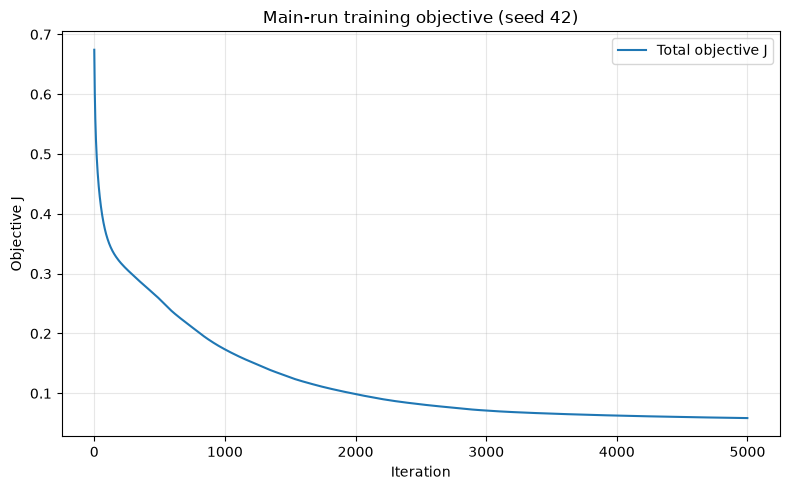

In [10]:
# Figure 1: total training objective for the selected NumPy main run.
plt.figure(figsize=(8, 5))
plt.plot(loss_history, color="tab:blue", label="Total objective J")
plt.xlabel("Iteration")
plt.ylabel("Objective J")
plt.title(f"Main-run training objective (seed {main_run['seed']})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



## Probability Map

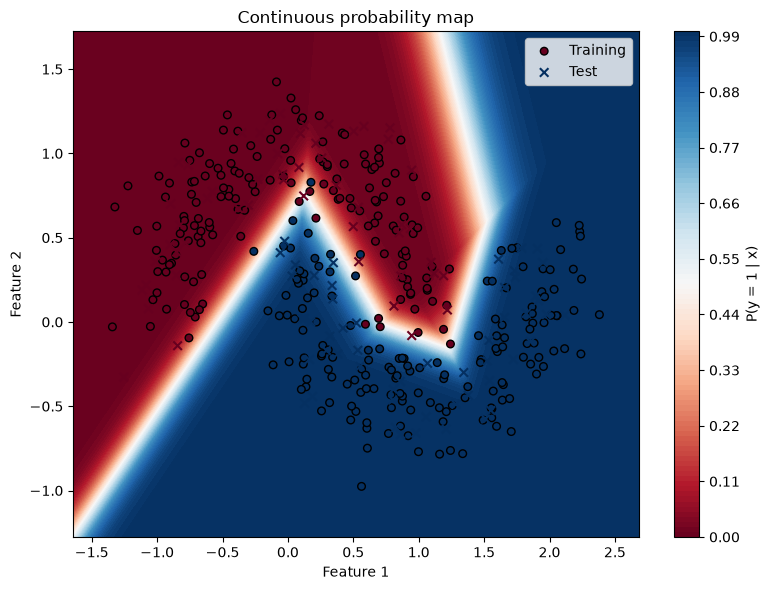

In [10]:
# All following coordinates are original coordinates; only grid_standardized enters the model.
X_train_original, X_test_original, xx, yy, grid_standardized = make_original_grid()
probability_grid = predict_proba(grid_standardized, parameters).reshape(xx.shape)

# Figure 2: continuous probability map.
plt.figure(figsize=(8, 6))
probability_map = plt.contourf(
    xx, yy, probability_grid, levels=np.linspace(0.0, 1.0, 101), cmap="RdBu", vmin=0.0, vmax=1.0
)
plt.colorbar(probability_map, label="P(y = 1 | x)")
plot_dataset(
    plt.gca(), X_train_original, Y_train, X_test_original, Y_test
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Continuous probability map")
plt.legend()
plt.tight_layout()
plt.show()



## Decision-Boundary Figure

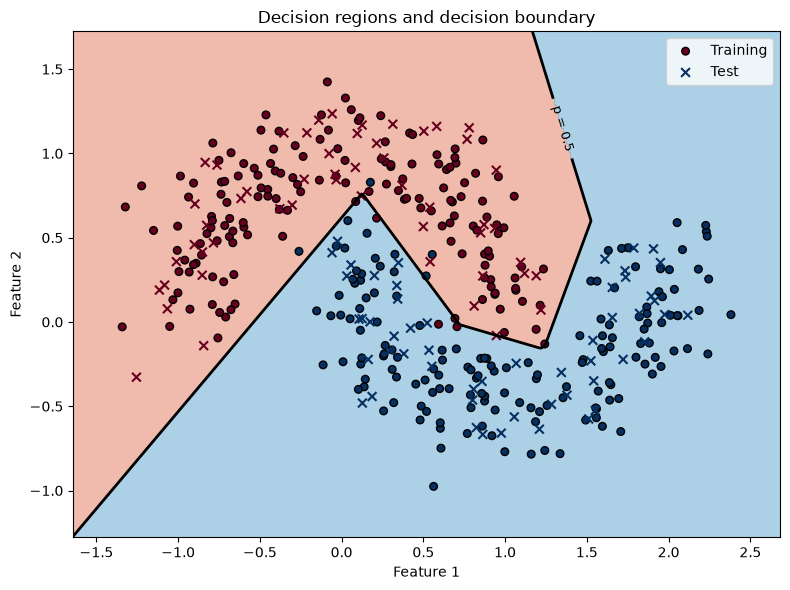

In [10]:
# Figure 3: class regions and the 0.5 decision boundary.
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, probability_grid >= 0.5, levels=[-0.5, 0.5, 1.5], cmap="RdBu", alpha=0.55)
boundary = plt.contour(xx, yy, probability_grid, levels=[0.5], colors="black", linewidths=2)
plt.clabel(boundary, fmt={0.5: "p = 0.5"}, inline=True, fontsize=9)
plot_dataset(
    plt.gca(),
    X_train_original,
    Y_train,
    X_test_original,
    Y_test,
    test_size=40,
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Decision regions and decision boundary")
plt.legend()
plt.tight_layout()
plt.show()


## Activity 5 - Independent Verification with PyTorch

PyTorch is used only after the NumPy implementation has passed Activity 4. The verification model is

$$
\operatorname{Linear}(2,4) \rightarrow \operatorname{ReLU} \rightarrow \operatorname{Linear}(4,1),
$$

and is evaluated in `float64`. PyTorch stores linear weights as `(output_features, input_features)`, so the NumPy weights are copied as $W_1^T$ and $W_2^T$; its one-dimensional biases receive flattened versions of $b_1$ and $b_2$. Transposition does not change a squared Frobenius norm, so the explicitly computed PyTorch penalty is exactly the NumPy weight-only L2 term. Biases are never regularized.

The first comparison copies the final NumPy main-run parameters into PyTorch and compares logits, probabilities, the full objective, and all gradients on a fixed mini-batch. The second comparison starts both implementations from the same main-seed initialization, uses full-batch gradient descent with the same hyperparameters, and compares complete loss trajectories, final boundaries, and test accuracies.


In [7]:
import torch
from torch import nn
import torch.nn.functional as F


torch.manual_seed(main_run["seed"])


class TorchMLP(nn.Module):
    """PyTorch equivalent of the NumPy 2 -> 4 -> 1 network."""

    def __init__(self):
        """Create the two fully connected layers."""
        super().__init__()
        self.fc1 = nn.Linear(2, 4)
        self.fc2 = nn.Linear(4, 1)

    def forward(self, X):
        """Return output logits for a batch of input samples."""
        Z1 = self.fc1(X)
        A1 = F.relu(Z1)
        Z2 = self.fc2(A1)
        return Z2


def copy_numpy_parameters_to_torch(model, numpy_parameters):
    """Copy NumPy's (input, output) weights into PyTorch's (output, input) storage."""
    with torch.no_grad():
        model.fc1.weight.copy_(torch.from_numpy(numpy_parameters["W1"].T))
        model.fc1.bias.copy_(torch.from_numpy(numpy_parameters["b1"].reshape(-1)))
        model.fc2.weight.copy_(torch.from_numpy(numpy_parameters["W2"].T))
        model.fc2.bias.copy_(torch.from_numpy(numpy_parameters["b2"].reshape(-1)))


def torch_objective(logits, targets, model, lambda_):
    """The same mean BCE + weight-only L2 objective as the NumPy implementation."""
    sample_count = targets.shape[0]
    bce_loss = F.binary_cross_entropy_with_logits(
        logits, targets, reduction="mean"
    )
    l2_penalty = lambda_ / (2.0 * sample_count) * (
        torch.sum(model.fc1.weight ** 2) + torch.sum(model.fc2.weight ** 2)
    )
    total_loss = bce_loss + l2_penalty
    return total_loss, bce_loss, l2_penalty


def comparison_metrics(left, right):
    """Return absolute and relative differences between two arrays."""
    left = np.asarray(left, dtype=np.float64)
    right = np.asarray(right, dtype=np.float64)
    difference = left - right
    return {
        "max_abs": np.max(np.abs(difference)),
        "relative": np.linalg.norm(difference)
        / (np.linalg.norm(left) + np.linalg.norm(right) + 1e-12),
    }




In [8]:
# Fixed mini-batch and exact copy of the final NumPy main-run parameters.
mini_batch_indices = np.arange(32)
X_mini = X_train[mini_batch_indices]
Y_mini = Y_train[mini_batch_indices]
print(f"Fixed mini-batch indices: {mini_batch_indices.tolist()}")

numpy_probabilities, numpy_cache = forward_propagation(X_mini, parameters)
numpy_objective, _, _ = compute_loss(Y_mini, numpy_cache["Z2"], parameters, lambda_)
numpy_gradients = backward_propagation(X_mini, Y_mini, parameters, numpy_cache, lambda_)

torch_model = TorchMLP().double()
copy_numpy_parameters_to_torch(torch_model, parameters)
X_mini_torch = torch.from_numpy(X_mini).to(dtype=torch.float64)
Y_mini_torch = torch.from_numpy(Y_mini).to(dtype=torch.float64)

torch_model.zero_grad()
torch_logits = torch_model(X_mini_torch)
torch_probabilities = torch.sigmoid(torch_logits)
torch_total_objective, _, _ = torch_objective(torch_logits, Y_mini_torch, torch_model, lambda_)
torch_total_objective.backward()

torch_gradients = {
    "dW1": torch_model.fc1.weight.grad.detach().numpy().T,
    "db1": torch_model.fc1.bias.grad.detach().numpy().reshape(1, -1),
    "dW2": torch_model.fc2.weight.grad.detach().numpy().T,
    "db2": torch_model.fc2.bias.grad.detach().numpy().reshape(1, -1),
}

verification_items = {
    "logits Z2": (numpy_cache["Z2"], torch_logits.detach().numpy()),
    "probabilities Y_hat": (numpy_probabilities, torch_probabilities.detach().numpy()),
    "objective J": (np.array([numpy_objective]), np.array([torch_total_objective.item()])),
    **{name: (numpy_gradients[name], torch_gradients[name]) for name in numpy_gradients},
}

print("\nNumPy versus PyTorch verification (float64)")
verification_results = {}
for name, (numpy_value, torch_value) in verification_items.items():
    metrics = comparison_metrics(numpy_value, torch_value)
    verification_results[name] = metrics
    print(f"{name:22s} max abs = {metrics['max_abs']:.3e}, relative = {metrics['relative']:.3e}")

assert all(
    metrics["max_abs"] < 1e-10 and metrics["relative"] < 1e-10
    for metrics in verification_results.values()
), "NumPy and PyTorch verification did not agree to float64 precision."


Fixed mini-batch indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]

NumPy versus PyTorch verification (float64)
logits Z2              max abs = 5.329e-15, relative = 8.340e-17
probabilities Y_hat    max abs = 1.388e-17, relative = 1.791e-18
objective J            max abs = 1.145e-16, relative = 2.130e-15
dW1                    max abs = 4.337e-19, relative = 2.132e-17
db1                    max abs = 1.735e-18, relative = 6.461e-17
dW2                    max abs = 1.735e-18, relative = 1.390e-16
db2                    max abs = 4.337e-19, relative = 1.208e-16


## PyTorch Training Comparison

Maximum |J_NumPy(t) - J_PyTorch(t)|: 1.110e-16
NumPy test accuracy:   0.9810
PyTorch test accuracy: 0.9810


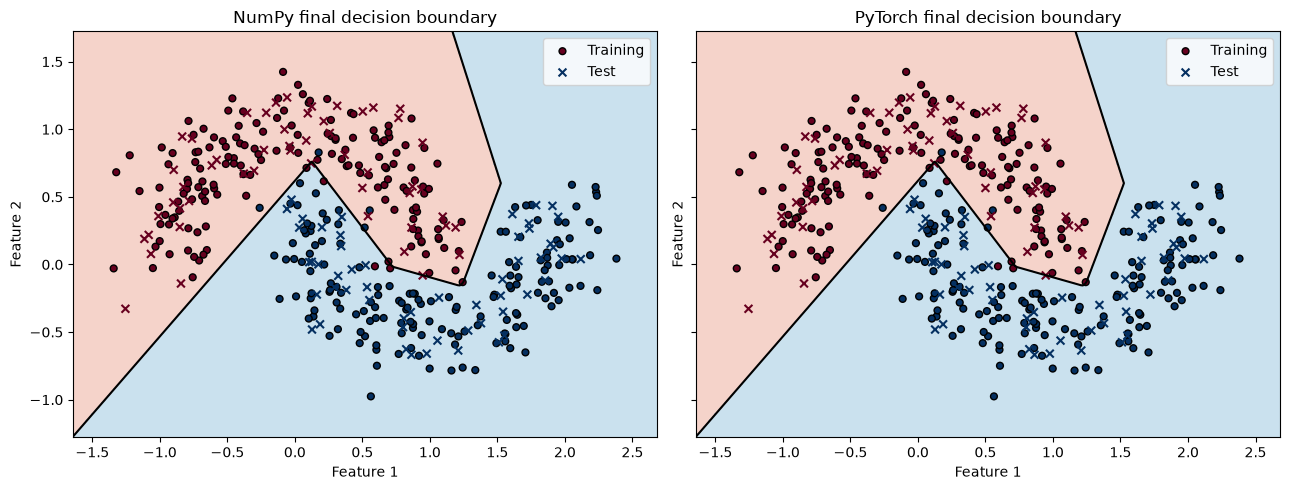

In [9]:
# Train PyTorch from the same initialization used by the NumPy main run.
initial_main_parameters = initialize_parameters(seed=main_run["seed"])
torch_training_model = TorchMLP().double()
copy_numpy_parameters_to_torch(torch_training_model, initial_main_parameters)
X_train_torch = torch.from_numpy(X_train).to(dtype=torch.float64)
Y_train_torch = torch.from_numpy(Y_train).to(dtype=torch.float64)
torch_loss_history = []

for _ in range(epochs):
    torch_training_model.zero_grad()
    logits = torch_training_model(X_train_torch)
    total_objective, _, _ = torch_objective(logits, Y_train_torch, torch_training_model, lambda_)
    total_objective.backward()
    with torch.no_grad():
        for tensor in torch_training_model.parameters():
            tensor -= learning_rate * tensor.grad
    torch_loss_history.append(total_objective.item())

trajectory_difference = np.max(np.abs(np.asarray(loss_history) - np.asarray(torch_loss_history)))
print(f"Maximum |J_NumPy(t) - J_PyTorch(t)|: {trajectory_difference:.3e}")

with torch.no_grad():
    torch_test_probabilities = torch.sigmoid(
        torch_training_model(torch.from_numpy(X_test).to(dtype=torch.float64))
    ).numpy()
torch_test_accuracy = np.mean((torch_test_probabilities >= 0.5).astype(np.int64) == Y_test)
numpy_test_accuracy = np.mean(predict(X_test, parameters) == Y_test)
print(f"NumPy test accuracy:   {numpy_test_accuracy:.4f}")
print(f"PyTorch test accuracy: {torch_test_accuracy:.4f}")

# Compare the final decision boundaries from the same original-coordinate grid.
X_train_original, X_test_original, xx, yy, grid_standardized = make_original_grid()
numpy_grid_probabilities = predict_proba(grid_standardized, parameters).reshape(xx.shape)
with torch.no_grad():
    torch_grid_probabilities = torch.sigmoid(
        torch_training_model(torch.from_numpy(grid_standardized).to(dtype=torch.float64))
    ).numpy().reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for axis, probability_grid, title in (
    (axes[0], numpy_grid_probabilities, "NumPy final decision boundary"),
    (axes[1], torch_grid_probabilities, "PyTorch final decision boundary"),
):
    axis.contourf(
        xx,
        yy,
        probability_grid >= 0.5,
        levels=[-0.5, 0.5, 1.5],
        cmap="RdBu",
        alpha=0.35,
    )
    axis.contour(xx, yy, probability_grid, levels=[0.5], colors="black", linewidths=1.5)
    plot_dataset(
        axis,
        X_train_original,
        Y_train,
        X_test_original,
        Y_test,
        train_size=24,
        test_size=32,
    )
    axis.set(title=title, xlabel="Feature 1", ylabel="Feature 2")
    axis.legend()
fig.tight_layout()
plt.show()


## Activity 7 - Conceptual Questions

##### Question 1 - Why does removing the ReLU cause the two-layer network to collapse into a single affine classifier?

Essentially, $Z_1$ and $Z_2$ are affine transformations of an input, meaning they warp an input and shift it with a bias. 

$$\mathbf{Z_1} = \mathbf{XW_1}+\mathbf{b_1}$$

This means that if i apply another transformation of this sort on top of the first one, i am not creating another transformation, but merely doing the same thing again. Effectively, after removing the ReLU, one could simply expand $Z_1$ inside $Z_2$ like so:

$$
\begin{aligned}
\mathbf Z_2
&=
(\mathbf X\mathbf W_1+\mathbf1\mathbf b_1)\mathbf W_2
+\mathbf1\mathbf b_2\\
&=
\mathbf X\mathbf W_1\mathbf W_2
+\mathbf1\mathbf b_1\mathbf W_2
+\mathbf1\mathbf b_2\\
&=
\mathbf X(\mathbf W_1\mathbf W_2)
+\mathbf1(\mathbf b_1\mathbf W_2+\mathbf b_2).
\end{aligned}
$$

This expanded equation is still one affine layer. Intuitively, resizing and adding pixels to an image does not introduce complex possibilities of distortion, like bending it or warping it in any way. Likewise, adding multiple stacked layers of affine distortion does nothing more than just shift the input. In summary, removing a ReLU makes the network mathematically equivalent to a single affine layer, which therefore cannot represent anything more complex than a linear decision boundary.

##### Question 2 - Why does the gradient with respect to a weight matrix have the same shape as the weight matrix?

The gradient must have the same shape as the weight matrix because there must be one gradient for each weight, so that it mathematically represents the variation of each weight. Backpropagation as a concept is to trace the prediction error backwards through the network to find out exactly how much each parameter is at fault for that error. Therefore, if i want to know how each weight affects loss, naturally the matrix that represents that gradient needs to be of the same dimensions as the weight matrix itself.

##### Question 3 - Explain why backpropagation through Z = AW + 1b uses WT to obtain dA.

Let's suppose $\mathbf{A}$ has $h$ hidden features and $\mathbf{Z}$ has $o$ outputs, meaning that:

$$\begin{align} \mathbf{A}: m \times h && \mathbf{W}: h \times o && \mathbf{Z}: m \times o\end{align}$$

to obtain $d\mathbf{A}$ we must transform those o dimensions back into h dimensions, in matrix dimensions:

$$(m \times o)(o \times h) = m \times h$$

Now, since $\mathbf{W}$ has dimensions $h \times o$, to achieve the required dimensions, we must transpose it.

##### Question 4 - Why is the bias gradient a sum across samples?

For any output, the forward operation is a weighted input for a sample, plus a bias.

$$Z_i = W_i + b$$

The same value is added across all outputs. During backpropagation, since $b$ affects all logits, its total effect must be accounted for 

$$\frac{\partial J}{\partial b} = \sum_{i=1}^{m} \frac{\partial J}{\partial Z_i} \frac{\partial Z_i}{\partial b}$$

Therefore, $db = \sum^m_{i = 1} dZ_i$.

##### Question 5 - What is the purpose of numerical gradient checking? What can it detect that observing a decreasing training loss cannot guarantee?

Numerical gradient checking is an independent verification of the gradients produced by backpropagation. For a given parameter, NGC slightly increases and decreases it and observes the objective change. The estimate is then compared to the analytical derivation of the gradient. If both agree, the backpropagation is likely correct. A decreasing training loss cannot guarantee that a gradient calculation is correct, because a partially correct gradient can still produce a net decrease in the training loss. NGC is, therefore, a trustworthy sanity check.

##### Question 6 - Which quantities must be cached during the forward pass and why are they required during backpropagation?

$\mathbf{Z_1}$, $\mathbf{A_1}$, $\mathbf{Z_2}$, and $\mathbf{\hat{Y}}$. This happens because these values are required for certain calculations during backpropagation. $\mathbf{\hat{Y}}$ is required for calculating the output error, $\mathbf{A_1}$ is required for the output weight gradient, and $\mathbf{Z_1}$ is required to determine which activation units were active and may backpropagate. $\mathbf{Z_2}$ is required to compute the numerically stable BCE loss.


## Final Discussion

This assignment was developed to solidify the concepts of forward passing a network model, and using backpropagation to opimize the network parameters in an effort to minimize the prediction loss during training. For the development of the code pertaining to the training and modelling side of the assignment, some dificulty was encountered in coding. Because of this, Codex was used to code models using the derivations present as reference. All AI assisted code was reviewed and audited by me to make sure math was consistent.